# Mira por dentro el RAG de tu proyecto

**Abre este `.ipynb` en Google Colab → Archivo → Subir notebook. Ejecuta las celdas en orden.**
Basta un entorno de CPU; no necesitas GPU, claves de API, dataset de imágenes ni subir el repositorio.
La primera instalación necesita internet. El modo semántico opcional también descarga un modelo.

Este notebook incluye una **instantánea de los 23 Markdown y del `kb.py` real del proyecto**.
Reconstruye una copia del índice en Colab: **no abre ni sincroniza la base de tu PC**.
No contiene `.env`, imágenes ni credenciales. Si cambias los documentos locales, regenera el notebook
con `python notebooks/_build_rag_inspector.py` antes de volver a subirlo.

## 1. ¿Dónde está la «base RAG»?

| Pieza | Archivo o carpeta del proyecto | Función |
|---|---|---|
| Conocimiento legible | `src/automl_agents/knowledge/*.md` | 11 fichas de arquitecturas y 12 guías |
| Indexación y búsqueda | `src/automl_agents/kb.py` | Calcula vectores, guarda documentos y recupera por similitud |
| Índice persistido de la web | `runs/.chroma/` (o `$AUTOML_RUNS_DIR/.chroma/`) | `chroma.sqlite3` y archivos del índice vectorial |
| Consultas del sistema | `Pipeline.n_retrieve()` en `pipeline.py` | Busca según el perfil y caso de uso |
| Uso de evidencia en generación | `propose_llm()` en `candidates.py` | Envía textos recuperados al LLM para proponer candidatas |
| Preguntas de evaluación | `knowledge/reference_queries.json` | 10 consultas y sus IDs relevantes; no se indexa como documento |

**RAG es el proceso completo**, no un único archivo: documentos → vectores → recuperación →
contexto para el LLM → propuesta. Chroma es el almacén; los Markdown son la fuente legible.
Los PDF de `papers/` **no se incorporan automáticamente**: `_load()` solo lee `knowledge/*.md`.
En esta versión cada Markdown se indexa completo como un registro; no hay partición en fragmentos.

La web configura persistencia. En cambio, `RunConfig.kb_persist_dir` vale `None` por defecto:
la CLI normal y `kb-eval` usan Chroma en memoria y reconstruyen la base al iniciar.
En la inspección local del 19/10/2026 existía `kb_hash`, con 23 registros de 512 dimensiones.


## 2. Instalar solo lo necesario para inspeccionar

Usamos la misma versión de Chroma comprobada localmente. No instalamos todo el proyecto:
así evitamos cargar entrenamiento, TensorFlow, Optuna y el servidor web.
Si Colab pide reiniciar la sesión tras instalar, hazlo y continúa desde esta celda.


In [ ]:
import subprocess
import sys

subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "chromadb==1.5.9"])


## 3. Restaurar la copia incluida

La siguiente celda contiene los textos y el código original como un diccionario de Python,
junto con sus huellas SHA-256. Puedes desplegarla para leerlos. Solo escribe en una carpeta temporal.
`contexto/` sirve para leer cómo se integra el RAG; esos módulos no se ejecutan.


In [1]:
SNAPSHOT = {'kb.py': '"""Base de conocimiento RAG sobre ChromaDB (R1.1).\n\nLos embeddings se calculan fuera de Chroma y se le pasan explícitamente, de modo que\nel backend de embeddings sea intercambiable sin depender de la versión de Chroma:\n  - "sentence-transformers": modelo multilingüe (recomendado; `pip install .[embeddings]`)\n  - "hash": embeddings léxicos deterministas, sin descargas (modo offline / tests)\n  - "auto": intenta el primero y cae al segundo.\n"""\nfrom __future__ import annotations\n\nimport hashlib\nimport json\nimport math\nimport re\nimport unicodedata\nfrom dataclasses import dataclass\nfrom pathlib import Path\n\nimport chromadb\n\nKNOWLEDGE_DIR = Path(__file__).parent / "knowledge"\n_STOP = set(\n    "a al algo de del la las el los un una unos unas y o u e en con por para que se su sus es son "\n    "como mas menos muy sin sobre entre lo le les si no ni the of and or to in for with is are".split()\n)\n\n\ndef _norm(text: str) -> list[str]:\n    text = unicodedata.normalize("NFKD", text.lower())\n    text = "".join(c for c in text if not unicodedata.combining(c))\n    toks = re.findall(r"[a-z0-9]+", text)\n    return [t[:5] for t in toks if t not in _STOP and len(t) > 1]  # stemming por prefijo\n\n\nclass HashEmbedder:\n    name = "hash"\n    dim = 512\n\n    def embed(self, texts: list[str]) -> list[list[float]]:\n        out = []\n        for t in texts:\n            v = [0.0] * self.dim\n            toks = _norm(t)\n            feats = toks + [f"{a}_{b}" for a, b in zip(toks, toks[1:])]\n            for f in feats:\n                h = int(hashlib.md5(f.encode()).hexdigest(), 16)\n                v[h % self.dim] += 1.0 if "_" not in f else 0.5\n            v = [math.log1p(x) for x in v]\n            n = math.sqrt(sum(x * x for x in v)) or 1.0\n            out.append([x / n for x in v])\n        return out\n\n\nclass SentenceTransformerEmbedder:\n    name = "st"\n\n    def __init__(self, model="paraphrase-multilingual-MiniLM-L12-v2"):\n        from sentence_transformers import SentenceTransformer\n\n        self._m = SentenceTransformer(model)\n\n    def embed(self, texts):\n        return self._m.encode(texts, normalize_embeddings=True).tolist()\n\n\ndef make_embedder(backend: str = "auto"):\n    if backend in ("auto", "sentence-transformers"):\n        try:\n            return SentenceTransformerEmbedder()\n        except Exception:\n            if backend != "auto":\n                raise\n    return HashEmbedder()\n\n\n@dataclass\nclass Doc:\n    id: str\n    title: str\n    text: str\n    kind: str\n    score: float = 0.0\n\n    def to_dict(self):\n        return {"id": self.id, "title": self.title, "kind": self.kind, "score": round(self.score, 3)}\n\n\nclass KnowledgeBase:\n    def __init__(self, persist_dir: str | Path | None = None, backend: str = "auto",\n                 knowledge_dir: Path = KNOWLEDGE_DIR):\n        self.embedder = make_embedder(backend)\n        self.knowledge_dir = Path(knowledge_dir)\n        if persist_dir:\n            Path(persist_dir).mkdir(parents=True, exist_ok=True)\n            self.client = chromadb.PersistentClient(path=str(persist_dir))\n        else:\n            self.client = chromadb.EphemeralClient()\n        # El nombre incluye el backend: cada uno tiene su propia dimensionalidad.\n        self.collection = self.client.get_or_create_collection(\n            f"kb_{self.embedder.name}", embedding_function=None, metadata={"hnsw:space": "cosine"}\n        )\n        self._docs: dict[str, Doc] = {}\n        self.build()\n\n    def _load(self) -> list[Doc]:\n        docs = []\n        for p in sorted(self.knowledge_dir.glob("*.md")):\n            lines = p.read_text(encoding="utf-8").strip().splitlines()\n            title = lines[0].lstrip("# ").strip()\n            docs.append(Doc(p.stem, title, "\\n".join(lines[1:]).strip(), p.stem.split("_")[0]))\n        return docs\n\n    def build(self) -> int:\n        docs = self._load()\n        self._docs = {d.id: d for d in docs}\n        texts = [f"{d.title}. {d.text}" for d in docs]\n        self.collection.upsert(\n            ids=[d.id for d in docs], documents=texts,\n            embeddings=self.embedder.embed(texts),\n            metadatas=[{"title": d.title, "kind": d.kind} for d in docs],\n        )\n        return len(docs)\n\n    def query(self, text: str, k: int = 3) -> list[Doc]:\n        res = self.collection.query(query_embeddings=self.embedder.embed([text]), n_results=k)\n        out = []\n        for i, dist in zip(res["ids"][0], res["distances"][0]):\n            d = self._docs[i]\n            out.append(Doc(d.id, d.title, d.text, d.kind, score=1.0 - float(dist)))\n        return out\n\n    def retrieve_many(self, queries: list[str], k: int = 3) -> list[Doc]:\n        seen: dict[str, Doc] = {}\n        for q in queries:\n            for d in self.query(q, k):\n                if d.id not in seen or d.score > seen[d.id].score:\n                    seen[d.id] = d\n        return sorted(seen.values(), key=lambda d: -d.score)\n\n    def evaluate(self, reference: list[dict] | None = None, k: int = 3) -> dict:\n        """Precisión@k y exhaustividad@k frente a un conjunto de referencia etiquetado a mano."""\n        if reference is None:\n            reference = json.loads((self.knowledge_dir / "reference_queries.json").read_text("utf-8"))\n        precs, recs = [], []\n        for item in reference:\n            got = {d.id for d in self.query(item["query"], k)}\n            rel = set(item["relevant"])\n            hit = len(got & rel)\n            precs.append(hit / k)\n            recs.append(hit / len(rel))\n        return {\n            "k": k, "n_queries": len(reference), "backend": self.embedder.name,\n            "precision_at_k": round(sum(precs) / len(precs), 3),\n            "recall_at_k": round(sum(recs) / len(recs), 3),\n        }\n', 'knowledge/arch_convnexttiny.md': '# ConvNeXtTiny (Keras Applications)\n\nRed convolucional moderna de unos 28.6 millones de parámetros inspirada en los transformers de visión. Alta exactitud en transferencia de aprendizaje, pero requiere GPU con más memoria y entrenamiento más lento. Recomendable con datasets medianos o grandes y recursos medios o altos. Nivel de recursos: medio.\n', 'knowledge/arch_densenet121.md': '# DenseNet121 (Keras Applications)\n\nRed de unos 8.1 millones de parámetros con conexiones densas que reutilizan características. Tiene pocos parámetros pero consume bastante memoria de activaciones durante el entrenamiento, lo que puede limitar el tamaño de lote en GPU de 4 GB. Buena con datasets pequeños por su eficiencia de parámetros. Nivel de recursos: bajo a medio.\n', 'knowledge/arch_efficientnetb0.md': '# EfficientNetB0 (Keras Applications)\n\nRed de unos 5.3 millones de parámetros obtenida con escalado compuesto de profundidad, ancho y resolución. Buen equilibrio entre exactitud y costo computacional a 224x224. Es un backbone de referencia para transferencia de aprendizaje en clasificación de imágenes con datasets pequeños o medianos y funciona bien con GPU de 4 GB. Nivel de recursos: bajo.\n', 'knowledge/arch_efficientnetv2b0.md': '# EfficientNetV2B0 (Keras Applications)\n\nVersión de segunda generación de EfficientNet, unos 7.2 millones de parámetros, con entrenamiento más rápido y mejor exactitud que EfficientNetB0 en pruebas de referencia. Recomendada como primera opción cuando se busca la mejor exactitud sin salir del rango de modelos ligeros. Buena para datasets pequeños y medianos con transferencia de aprendizaje. Nivel de recursos: bajo.\n', 'knowledge/arch_inceptionv3.md': '# InceptionV3 (Keras Applications)\n\nRed de unos 23.9 millones de parámetros con módulos Inception y resolución nativa 299x299. Buen desempeño histórico en clasificación de imágenes, pero de mayor costo que las opciones ligeras y con menor eficiencia que EfficientNet. Se justifica solo con recursos medios y datasets medianos o grandes. Nivel de recursos: medio.\n', 'knowledge/arch_mobilenetv2.md': '# MobileNetV2 (Keras Applications)\n\nArquitectura liviana de unos 3.5 millones de parámetros con bloques residuales invertidos y convoluciones separables por profundidad. Resolución nativa 224x224. Consume poca memoria de video y entrena rápido, por lo que es una opción segura para equipos con poca GPU o solo CPU. Con transferencia de aprendizaje suele rendir bien en datasets pequeños y medianos de clasificación de imágenes. Nivel de recursos: bajo.\n', 'knowledge/arch_mobilenetv3small.md': '# MobileNetV3Small (Keras Applications)\n\nVariante más pequeña de MobileNetV3, unos 2.5 millones de parámetros, diseñada para dispositivos móviles y latencia mínima. Incluye el preprocesamiento dentro del modelo. Es la opción más rápida y ligera del catálogo, pero su capacidad de representación es menor, así que puede quedar corta en problemas con clases visualmente muy parecidas. Nivel de recursos: bajo.\n', 'knowledge/arch_nasnetmobile.md': '# NASNetMobile (Keras Applications)\n\nArquitectura de unos 5.3 millones de parámetros hallada mediante búsqueda de arquitecturas neuronales (NAS). Es liviana pero suele ser más lenta de entrenar que MobileNet o EfficientNet por su estructura de celdas complejas, y su exactitud rara vez la supera. Se considera una alternativa de segunda línea. Nivel de recursos: bajo.\n', 'knowledge/arch_resnet50v2.md': '# ResNet50V2 (Keras Applications)\n\nRed residual de unos 25.6 millones de parámetros. Es un backbone robusto y ampliamente probado en clasificación de imágenes, con comportamiento de entrenamiento estable. Exige más memoria y tiempo que los modelos ligeros; conviene cuando hay GPU de 8 GB o más o el dataset es mediano o grande. Nivel de recursos: medio.\n', 'knowledge/arch_vgg16.md': '# VGG16 (Keras Applications)\n\nRed clásica de unos 138 millones de parámetros, la mayoría en las capas densas finales. Es ineficiente frente a arquitecturas modernas: mucha memoria, entrenamiento lento y exactitud similar o inferior a modelos diez veces más pequeños. No se recomienda para empresas con recursos limitados. Nivel de recursos: alto.\n', 'knowledge/arch_xception.md': '# Xception (Keras Applications)\n\nRed de unos 22.9 millones de parámetros basada en convoluciones separables por profundidad, con resolución nativa 299x299. La resolución mayor aumenta el costo de memoria y tiempo. Ofrece buena exactitud con datasets medianos o grandes cuando hay GPU con memoria suficiente. Nivel de recursos: medio.\n', 'knowledge/guide_batch_size.md': '# Tamaño de lote\n\nEl tamaño de lote está limitado por la memoria de video. En GPU de 4 GB, como una GTX 1650, se recomiendan lotes de 16 o 32 con modelos ligeros; lotes de 64 suelen exceder la memoria con resoluciones de 224x224 o mayores. En GPU de 8 GB o más se pueden usar lotes de 32 a 64.\n', 'knowledge/guide_class_imbalance.md': '# Desbalance de clases\n\nCuando una clase tiene mucho más ejemplos que otra, la exactitud global engaña. Se recomienda ponderar la función de pérdida con pesos de clase inversamente proporcionales a la frecuencia, usar aumento de datos en las clases minoritarias y evaluar con F1 macro, matriz de confusión y recall por clase en lugar de solo exactitud.\n', 'knowledge/guide_data_augmentation.md': '# Aumento de datos\n\nAplicar transformaciones aleatorias como volteo horizontal, rotaciones suaves y zoom durante el entrenamiento aumenta la diversidad efectiva del dataset y reduce el sobreajuste. Es especialmente útil con pocos datos. Debe evitarse el volteo o la rotación cuando alteran el significado de la clase, por ejemplo dígitos o texto.\n', 'knowledge/guide_dropout_regularization.md': '# Dropout y regularización\n\nEl dropout antes de la capa de clasificación reduce el sobreajuste. Valores de 0.2 a 0.4 son razonables con pocos datos; con muchos datos basta 0.0 a 0.2. Un dropout excesivo con datasets grandes puede provocar subajuste y ralentizar la convergencia.\n', 'knowledge/guide_early_stopping.md': '# Descarte temprano y parada anticipada\n\nDetener las configuraciones con mal desempeño parcial ahorra la mayor parte del cómputo de una búsqueda. Estrategias tipo Hyperband asignan pocos recursos a muchas configuraciones y continúan solo con las mejores. La parada anticipada por paciencia sobre la métrica de validación evita épocas inútiles y restaura los mejores pesos.\n', 'knowledge/guide_input_resolution.md': '# Resolución de entrada\n\nCada arquitectura tiene una resolución nativa, 224x224 en la mayoría y 299x299 en Xception e InceptionV3. Subir la resolución mejora el detalle pero aumenta el costo cuadráticamente. Si las imágenes del usuario son pequeñas, aumentar artificialmente su tamaño no aporta información. Con recursos limitados conviene usar la resolución nativa mínima.\n', 'knowledge/guide_large_dataset.md': '# Datasets grandes: muchas imágenes\n\nCon más de unas 10000 imágenes de entrenamiento se pueden considerar arquitecturas de mayor capacidad como ResNet50V2 o ConvNeXtTiny, siempre que los recursos lo permitan. El riesgo de sobreajuste baja, por lo que el dropout puede ser bajo de 0.0 a 0.2 y el aumento de datos es opcional.\n', 'knowledge/guide_learning_rate.md': '# Rangos de tasa de aprendizaje\n\nCon backbone congelado y optimizador Adam, la cabeza nueva admite tasas de aprendizaje relativamente altas, entre 3e-4 y 3e-3. Al entrenar toda la red desde cero conviene un rango menor, entre 1e-4 y 1e-3. Tasas de 1e-2 suelen ser inestables. La tasa de aprendizaje es el hiperparámetro con mayor impacto y debe buscarse en escala logarítmica.\n', 'knowledge/guide_limited_resources.md': '# Entrenamiento con recursos computacionales limitados\n\nPara pymes sin infraestructura propia, priorizar modelos ligeros de bajo consumo de memoria de video, lotes pequeños, backbone congelado y pocas épocas. Evaluar primero pocas configuraciones con presupuesto reducido y dedicar más cómputo solo a las prometedoras reduce costo de GPU. Se puede complementar con cómputo en la nube para configuraciones más exigentes.\n', 'knowledge/guide_metrics.md': '# Métricas de evaluación en clasificación de imágenes\n\nLa exactitud es adecuada con clases balanceadas. Con desbalance se recomienda F1 macro y matriz de confusión. Toda decisión de selección debe basarse en el conjunto de validación y reportarse el resultado final sobre un conjunto de prueba separado, para evitar sobreajuste al conjunto de validación durante la búsqueda de hiperparámetros.\n', 'knowledge/guide_small_dataset.md': '# Datasets pequeños: pocas imágenes por clase\n\nCon menos de unos 1000 imágenes de entrenamiento o pocas decenas por clase, conviene elegir arquitecturas ligeras con transferencia de aprendizaje, usar aumento de datos y dropout alto de 0.2 a 0.4 para evitar sobreajuste. Los modelos grandes tienden a sobreajustar con pocos datos y no aportan mejora. Usar validación estratificada.\n', 'knowledge/guide_transfer_learning.md': '# Transferencia de aprendizaje con pesos ImageNet\n\nReutilizar un backbone preentrenado en ImageNet y entrenar solo una cabeza de clasificación nueva es la estrategia más eficiente cuando hay pocas imágenes por clase. Se congela el backbone, se agrega pooling global, dropout y una capa densa softmax. Reduce mucho el tiempo de entrenamiento y la necesidad de datos etiquetados frente a entrenar desde cero.\n', 'knowledge/reference_queries.json': '[\n  {"query": "dataset con muy pocas imágenes por clase", "relevant": ["guide_small_dataset", "guide_transfer_learning", "guide_data_augmentation"]},\n  {"query": "qué hacer cuando una clase tiene muchos más ejemplos que otra", "relevant": ["guide_class_imbalance", "guide_metrics"]},\n  {"query": "tamaño de lote para GPU de 4 GB de memoria", "relevant": ["guide_batch_size", "guide_limited_resources"]},\n  {"query": "rango de tasa de aprendizaje para entrenar la cabeza con backbone congelado", "relevant": ["guide_learning_rate", "guide_transfer_learning"]},\n  {"query": "modelo muy grande con demasiados parámetros no recomendado para pymes", "relevant": ["arch_vgg16", "guide_limited_resources"]},\n  {"query": "detener configuraciones malas temprano para ahorrar cómputo", "relevant": ["guide_early_stopping", "guide_limited_resources"]},\n  {"query": "arquitectura más ligera para dispositivos móviles con latencia mínima", "relevant": ["arch_mobilenetv3small", "arch_mobilenetv2"]},\n  {"query": "muchas imágenes de entrenamiento, modelo de mayor capacidad", "relevant": ["guide_large_dataset", "arch_resnet50v2", "arch_convnexttiny"]},\n  {"query": "resolución 299 de entrada más costosa", "relevant": ["arch_xception", "arch_inceptionv3", "guide_input_resolution"]},\n  {"query": "qué métricas usar para evaluar el modelo y conjunto de prueba", "relevant": ["guide_metrics", "guide_class_imbalance"]}\n]\n', 'contexto/pipeline.py': '"""Grafo LangGraph que orquesta a los agentes (perfil → RAG → candidatas → búsqueda iterativa →\nevaluación → benchmark → reportes → empaquetado)."""\nfrom __future__ import annotations\n\nimport json\nimport traceback\nfrom typing import Any, TypedDict\n\nfrom langgraph.graph import END, START, StateGraph\n\nfrom . import candidates as cand_mod\nfrom . import controller, reporting\nfrom .benchmark import compute_benchmark\nfrom .catalog import CATALOG\nfrom .config import RunConfig\nfrom .dataset import profile_dataset\nfrom .events import RunLogger\nfrom .kb import KnowledgeBase\nfrom .llm import LLM\nfrom .packaging import build_artifact\nfrom .risk import assess_use_case\n\n\nclass State(TypedDict, total=False):\n    round: int\n    stop: bool\n    summary: dict\n\n\nclass Pipeline:\n    """Contexto compartido entre nodos (objetos pesados fuera del estado del grafo)."""\n\n    def __init__(self, cfg: RunConfig, kb: KnowledgeBase | None = None, llm: LLM | None = None):\n        self.cfg = cfg\n        cfg.run_dir.mkdir(parents=True, exist_ok=True)\n        (cfg.run_dir / "config.json").write_text(json.dumps(cfg.to_dict(), indent=2), encoding="utf-8")\n        self.log = RunLogger(cfg.run_dir)\n        self.llm = llm if llm is not None else LLM(cfg.llm_model, cfg.use_llm)\n        self.kb = kb or KnowledgeBase(cfg.kb_persist_dir, cfg.embedding_backend)\n        self.decisions: list[dict] = []\n        self.candidates: list = []\n\n    # ---- nodos ----\n    def n_profile(self, s: State) -> State:\n        self.profile, self.files = profile_dataset(self.cfg.dataset_dir, seed=self.cfg.seed)\n        self.risk = assess_use_case(self.cfg.use_case)\n        self.log.emit("perfil", f"Dataset: {self.profile.n_images} imágenes, {self.profile.n_classes} clases",\n                      profile=self.profile.to_dict(), risk=self.risk)\n        return {}\n\n    def n_retrieve(self, s: State) -> State:\n        p = self.profile\n        bucket = p.size_bucket()\n        q = [f"dataset {\'pequeño con pocas imágenes\' if bucket == \'small\' else \'grande con muchas imágenes\' if bucket == \'large\' else \'mediano\'} de clasificación de imágenes",\n             "rangos de tasa de aprendizaje y dropout", "tamaño de lote y memoria de GPU", "recursos computacionales limitados",\n             "arquitecturas ligeras con transferencia de aprendizaje", "descarte temprano de configuraciones", "métricas de evaluación"]\n        if p.imbalance_ratio > 1.5:\n            q.append("clases desbalanceadas")\n        if self.cfg.use_case:\n            q.append(self.cfg.use_case)\n        self.docs = self.kb.retrieve_many(q, k=3)\n        self.log.emit("rag", f"{len(self.docs)} documentos recuperados", docs=[d.to_dict() for d in self.docs])\n        return {}\n\n    def n_propose(self, s: State) -> State:\n        self.prop = cand_mod.propose(self.profile, self.docs, self.cfg, self.llm)\n        self.candidates = list(self.prop["candidates"])\n        sp = self.prop["space"]\n        reporting.write_criteria_report(self.cfg.run_dir, self.profile, self.prop, self.docs)\n        self.log.emit("candidatas", f"{len(self.candidates)} candidatas ({self.prop[\'mode\']}); espacio "\n                      f"{sp[\'total_configs\']}→{sp[\'candidate_configs\']} (-{sp[\'reduction_pct\']} %)",\n                      candidates=[c.architecture for c in self.candidates])\n        from .search import SearchEngine  # import diferido: TensorFlow es pesado\n        self.engine = SearchEngine(self.cfg, self.profile, self.files, self.log)\n        return {"round": 1, "stop": False}\n\n    def n_train(self, s: State) -> State:\n        self.engine.run_round(s["round"], self.candidates, self.cfg.trials_per_round)\n        return {}\n\n    def n_control(self, s: State) -> State:\n        r = s["round"]\n        self.candidates, decs, stop = controller.decide(r, self.candidates, self.engine.records, self.cfg)\n        self.decisions += decs\n        for d in decs:\n            self.log.emit("control", f"[ronda {r}] {d[\'candidate_id\']}: {d[\'action\']} — {d[\'reason\']}")\n        return {"round": r + 1, "stop": stop}\n\n    def n_evaluate(self, s: State) -> State:\n        from . import evaluation, trainer\n        recs, ev = self.engine.records, {}\n        for c in self.prop["candidates"]:\n            path = self.cfg.run_dir / "models" / f"{c.id}.keras"\n            if not path.exists():\n                continue\n            ds = trainer.batched(self.engine.base_ds("test", c), 64, 0, False, 0)\n            m = evaluation.evaluate_model(path, ds, self.engine.splits["test"][1], self.profile.classes)\n            ev[c.id] = {"architecture": c.architecture, "val_acc": round(self.engine.best_per_candidate[c.id], 4),\n                        "test": m}\n            self.log.emit("evaluacion", f"{c.architecture}: test acc={m[\'accuracy\']:.3f}, F1={m[\'f1_macro\']:.3f}")\n        if not ev:\n            raise RuntimeError("Ninguna configuración terminó el entrenamiento; revise el dataset o aumente el presupuesto.")\n        self.eval = ev\n        self.winner_id = max(ev, key=lambda k: (ev[k]["val_acc"], -CATALOG[ev[k]["architecture"]].params_m))\n        best = max((r for r in recs if r.get("saved_as_best") and r["candidate_id"] == self.winner_id),\n                   key=lambda r: r["val_acc"])\n        cand = next(c for c in self.prop["candidates"] if c.id == self.winner_id)\n        self.winner = {"candidate_id": self.winner_id, "architecture": cand.architecture,\n                       "img_size": cand.img_size, "params": best["params"], "val_acc": best["val_acc"]}\n        return {}\n\n    def n_benchmark(self, s: State) -> State:\n        self.bench = compute_benchmark(self.engine.records, self.cfg, self.prop["space"])\n        return {}\n\n    def n_report(self, s: State) -> State:\n        rd = self.cfg.run_dir\n        reporting.write_iterations(rd, self.decisions, self.engine.records)\n        reporting.write_resources_csv(rd, self.engine.records)\n        reporting.write_evaluation(rd, self.eval, self.winner_id)\n        reporting.write_benchmark(rd, self.bench)\n        reporting.write_final_report(rd, self.cfg, self.profile, self.prop, self.winner,\n                                     self.eval[self.winner_id], self.engine.records, self.risk, self.bench, self.llm)\n        self.log.emit("reportes", "Reportes generados")\n        return {}\n\n    def n_package(self, s: State) -> State:\n        art = build_artifact(self.cfg.run_dir, self.winner, self.profile.classes, self.eval[self.winner_id]["test"])\n        summary = {"run_id": self.cfg.run_id, "winner": self.winner, "test": {k: self.eval[self.winner_id]["test"][k] for k in ("accuracy", "f1_macro", "n_test")},\n                   "space": self.prop["space"], "benchmark": {k: self.bench[k] for k in ("trials_total", "trials_pruned", "saving_from_early_stopping_pct")},\n                   "mode": self.prop["mode"], "artifact": str(art)}\n        (self.cfg.run_dir / "run_summary.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8")\n        self.log.emit("listo", f"Modelo {self.winner[\'architecture\']} listo (test acc={summary[\'test\'][\'accuracy\']:.3f})")\n        return {"summary": summary}\n\n    def build(self):\n        g = StateGraph(State)\n        for name, fn in [("perfil", self.n_profile), ("rag", self.n_retrieve), ("candidatas", self.n_propose),\n                         ("entrenar", self.n_train), ("controlar", self.n_control), ("evaluar", self.n_evaluate),\n                         ("benchmark", self.n_benchmark), ("reportar", self.n_report), ("empaquetar", self.n_package)]:\n            g.add_node(name, fn)\n        g.add_edge(START, "perfil")\n        g.add_edge("perfil", "rag")\n        g.add_edge("rag", "candidatas")\n        g.add_edge("candidatas", "entrenar")\n        g.add_edge("entrenar", "controlar")\n        g.add_conditional_edges("controlar", lambda s: "evaluar" if s["stop"] else "entrenar",\n                                {"entrenar": "entrenar", "evaluar": "evaluar"})\n        g.add_edge("evaluar", "benchmark")\n        g.add_edge("benchmark", "reportar")\n        g.add_edge("reportar", "empaquetar")\n        g.add_edge("empaquetar", END)\n        return g.compile()\n\n\ndef run_pipeline(cfg: RunConfig, kb: KnowledgeBase | None = None, llm: LLM | None = None) -> dict:\n    pl = Pipeline(cfg, kb, llm)\n    try:\n        out = pl.build().invoke({}, config={"recursion_limit": 100})\n        return out["summary"]\n    except Exception as e:\n        pl.log.emit("error", f"{type(e).__name__}: {e}", trace=traceback.format_exc())\n        raise\n', 'contexto/candidates.py': '"""Agente generador de configuraciones candidatas (R1.2) y reporte de criterios (R1.3).\n\nModo "llm": el LLM razona sobre el perfil del dataset y los documentos recuperados (RAG).\nModo "reglas": heurística determinista basada en las mismas guías (sin API).\nEn ambos casos la salida se VALIDA contra el catálogo y la rejilla: el LLM no puede\nintroducir arquitecturas ni valores inexistentes (mitiga alucinaciones, sección 3.6.2).\n"""\nfrom __future__ import annotations\n\nimport json\nfrom dataclasses import asdict, dataclass\n\nfrom .catalog import (AUGMENT_GRID, BATCH_GRID, CATALOG, DROPOUT_GRID, LR_GRID, TIER_ALLOWED,\n                      full_space_size, space_size)\nfrom .config import RunConfig\nfrom .dataset import DatasetProfile\nfrom .kb import Doc\nfrom .llm import LLM\n\n\n@dataclass\nclass Candidate:\n    id: str\n    architecture: str\n    rationale: str\n    sources: list[str]\n    lr_values: list[float]\n    dropout_values: list[float]\n    batch_sizes: list[int]\n    augment_values: list[bool]\n    img_size: int\n\n    def to_dict(self):\n        return asdict(self)\n\n\ndef _subset(vals, grid, fallback):\n    ok = [v for v in (vals or []) if v in grid]\n    return ok or list(fallback)\n\n\ndef default_space(profile: DatasetProfile, cfg: RunConfig) -> dict:\n    bucket = profile.size_bucket(1 - cfg.val_fraction - cfg.test_fraction)\n    lr = [3e-4, 1e-3, 3e-3] if cfg.pretrained else [1e-4, 3e-4, 1e-3]\n    dropout = {"small": [0.2, 0.4], "medium": [0.0, 0.2, 0.4], "large": [0.0, 0.2]}[bucket]\n    batch = [16, 32] if cfg.resource_tier == "low" else [32, 64]\n    augment = [True] if bucket == "small" else [False, True]\n    return dict(lr_values=lr, dropout_values=dropout, batch_sizes=batch, augment_values=augment)\n\n\ndef _allowed(cfg: RunConfig) -> dict:\n    names = cfg.allowed_architectures or list(CATALOG)\n    tiers = TIER_ALLOWED[cfg.resource_tier]\n    ok, discarded = {}, []\n    for n in CATALOG:\n        s = CATALOG[n]\n        if n not in names:\n            discarded.append({"architecture": n, "reason": "Excluida por el usuario (lista de arquitecturas permitidas)."})\n        elif s.tier not in tiers:\n            discarded.append({"architecture": n, "reason": (\n                f"Excluida por recursos: ~{s.params_m}M de parámetros (nivel \'{s.tier}\') supera lo "\n                f"razonable para el nivel de recursos \'{cfg.resource_tier}\'.")})\n        else:\n            ok[n] = s\n    return ok, discarded\n\n\ndef _score(spec, bucket: str) -> float:\n    s = spec.prior\n    if bucket == "small":\n        s += 0.10 if spec.tier == "light" else -0.10\n    elif bucket == "large":\n        s += 0.05 if spec.tier == "medium" else 0.0\n    return s\n\n\ndef _img_size(spec, cfg):\n    return cfg.img_size_override or spec.input_size\n\n\ndef _src_for(arch: str, docs: list[Doc]) -> list[str]:\n    ids = [d.id for d in docs if d.id == f"arch_{arch.lower()}"]\n    ids += [d.id for d in docs if d.kind == "guide"][:3]\n    return ids\n\n\ndef propose_rules(profile, docs, cfg) -> tuple[list[Candidate], list[dict]]:\n    ok, discarded = _allowed(cfg)\n    bucket = profile.size_bucket(1 - cfg.val_fraction - cfg.test_fraction)\n    ranked = sorted(ok.values(), key=lambda s: -_score(s, bucket))\n    chosen, rest = ranked[: cfg.max_candidates], ranked[cfg.max_candidates:]\n    space = default_space(profile, cfg)\n    cands = []\n    for i, s in enumerate(chosen, 1):\n        why = (f"~{s.params_m}M parámetros, nivel de recursos \'{s.tier}\'; dataset {bucket} "\n               f"({profile.n_images} imágenes, {profile.n_classes} clases) → prioridad {_score(s, bucket):.2f}.")\n        cands.append(Candidate(f"c{i}", s.name, why, _src_for(s.name, docs), img_size=_img_size(s, cfg), **space))\n    for s in rest:\n        discarded.append({"architecture": s.name, "reason": (\n            f"Válida, pero fuera del top-{cfg.max_candidates} por prioridad "\n            f"({_score(s, bucket):.2f}) para un dataset {bucket}.")})\n    return cands, discarded\n\n\ndef propose_llm(profile, docs, cfg, llm: LLM) -> tuple[list[Candidate], list[dict]]:\n    ok, discarded = _allowed(cfg)\n    system = ("Eres un ingeniero de ML que acota el espacio de búsqueda de modelos de clasificación de imágenes. "\n              "Usa EXCLUSIVAMENTE la evidencia recuperada y el perfil del dataset. Justifica cada decisión.")\n    user = json.dumps({\n        "perfil_dataset": profile.to_dict(),\n        "caso_de_uso": cfg.use_case,\n        "nivel_recursos": cfg.resource_tier,\n        "preentrenado": cfg.pretrained,\n        "evidencia_recuperada": [{"id": d.id, "titulo": d.title, "texto": d.text} for d in docs],\n        "arquitecturas_permitidas": {n: {"params_m": s.params_m} for n, s in ok.items()},\n        "rejilla": {"lr": LR_GRID, "dropout": DROPOUT_GRID, "batch": BATCH_GRID, "augment": AUGMENT_GRID},\n        "instrucciones": (\n            f"Elige entre 1 y {cfg.max_candidates} arquitecturas permitidas. Devuelve JSON: "\n            \'{"candidatas":[{"arquitectura":str,"justificacion":str,"fuentes":[ids],"lr":[..],"dropout":[..],\'\n            \'"batch":[..],"augment":[..]}],"descartadas":[{"arquitectura":str,"razon":str}]}. \'\n            "Los valores deben salir de la rejilla; elige 2-3 valores por hiperparámetro."),\n    }, ensure_ascii=False)\n    data = llm.complete_json(system, user)\n    default = default_space(profile, cfg)\n    doc_ids = {d.id for d in docs}\n    cands = []\n    for item in data.get("candidatas", []):\n        a = item.get("arquitectura")\n        if a not in ok or any(c.architecture == a for c in cands):\n            continue\n        cands.append(Candidate(\n            f"c{len(cands)+1}", a, str(item.get("justificacion", ""))[:500],\n            [s for s in item.get("fuentes", []) if s in doc_ids],\n            _subset(item.get("lr"), LR_GRID, default["lr_values"]),\n            _subset(item.get("dropout"), DROPOUT_GRID, default["dropout_values"]),\n            _subset(item.get("batch"), BATCH_GRID, default["batch_sizes"]),\n            _subset(item.get("augment"), AUGMENT_GRID, default["augment_values"]),\n            _img_size(ok[a], cfg)))\n        if len(cands) == cfg.max_candidates:\n            break\n    if not cands:\n        raise ValueError("El LLM no propuso candidatas válidas")\n    picked = {c.architecture for c in cands}\n    reasons = {d.get("arquitectura"): d.get("razon") for d in data.get("descartadas", [])}\n    for n in ok:\n        if n not in picked:\n            discarded.append({"architecture": n, "reason": reasons.get(n) or "No seleccionada por el agente."})\n    return cands, discarded\n\n\ndef propose(profile, docs, cfg, llm: LLM | None) -> dict:\n    mode, note = "reglas", ""\n    if llm is not None and llm.available:\n        try:\n            cands, discarded = propose_llm(profile, docs, cfg, llm)\n            mode = "llm"\n        except Exception as e:  # cae a reglas: la ejecución nunca depende del LLM\n            note = f"Fallo del LLM ({type(e).__name__}: {str(e)[:300]}); se usó el generador por reglas."\n            cands, discarded = propose_rules(profile, docs, cfg)\n    else:\n        cands, discarded = propose_rules(profile, docs, cfg)\n    total, reduced = full_space_size(), space_size(cands)\n    return {\n        "mode": mode, "note": note,\n        "candidates": cands, "discarded": discarded,\n        "space": {"total_configs": total, "candidate_configs": reduced,\n                  "reduction_pct": round(100 * (1 - reduced / total), 1)},\n        "criteria": {\n            "dataset_bucket": profile.size_bucket(1 - cfg.val_fraction - cfg.test_fraction),\n            "resource_tier": cfg.resource_tier, "pretrained": cfg.pretrained,\n            "retrieved_docs": [],\n        },\n    }\n'}

MANIFEST = {'kb.py': '90474ccbfb23c491e9717bef30c3fa62deabfb69150d30a7860dae5d8f34e8ee', 'knowledge/arch_convnexttiny.md': 'be050044dc2c9770a182b1e23cf30c8702320edfb36177e2a94776d0229692b7', 'knowledge/arch_densenet121.md': '9964325f67c73edc1a74d9ae2541e2e585d26a2b1cdec4dd70ffeffae77eb819', 'knowledge/arch_efficientnetb0.md': 'be15afad49e55c76e7d0493f00db0615c5e59a20dd6e6cd6701e75683ea98e59', 'knowledge/arch_efficientnetv2b0.md': '76f7ae053058e0151d90b0c8ada1f06178cb40d7b91475e22a4bbbd2bf49a08f', 'knowledge/arch_inceptionv3.md': 'feb83e71168ad65864767aab0a7632e8adee6bdcb46fcc0578dbf709ef96b05b', 'knowledge/arch_mobilenetv2.md': 'd68331afd6e639abcb484b414002000d1b4fa1b5797d66a5807e95d7a57b2726', 'knowledge/arch_mobilenetv3small.md': '3e33d4f846241b6ef7d346cbca58cde07460da380fb7c8235ed2b9fe77869a8e', 'knowledge/arch_nasnetmobile.md': '0dfe07297e6b9e57f0423ad101b9623005f24978971711ce67e12e52d867c5e2', 'knowledge/arch_resnet50v2.md': 'c5846faa9e4eb00244bb7f1828ced18650ba6cd764ca0e11b8a671dc3c510143', 'knowledge/arch_vgg16.md': '39345e58fe0811388cd35333411a4337ffeae363e4e73c88bd8d78bc043600d5', 'knowledge/arch_xception.md': 'aa88da9e104b7e28f2d223a4a42650d5dfe2b111d709c191c29741770b5daf81', 'knowledge/guide_batch_size.md': '1f694a4d066fc90ba1c6f6869bb328b13e1091c512636e7871532a786ef08dc4', 'knowledge/guide_class_imbalance.md': 'a97e3674147046eb0bd8549c8bf268eaaf97abbaf0d5c1150c235bd6e3fdf862', 'knowledge/guide_data_augmentation.md': '3eccdd8b1efc2fda84a6e4b2047331220153ff9cbafaa7ee7582d418cd789474', 'knowledge/guide_dropout_regularization.md': 'a54f9e695dc2be43766395cba8bb9ea88b23a5b99c37c5cc551ef05d9791ccea', 'knowledge/guide_early_stopping.md': 'f3932fc21394c8bd2429f69b1e8436c12d67664d27f3bd87590eefc92cde1127', 'knowledge/guide_input_resolution.md': '95c1db1291f04a58f19dffff3f129100f58adee30b241d3743fa438d423cac09', 'knowledge/guide_large_dataset.md': 'efa2ca1841b18c0183525e7eeec92421f0682f9fd680c7e391f8d5f0dc1666cf', 'knowledge/guide_learning_rate.md': 'f68d37c59419cb7fb3ed13344f0aadc09addcc169ba9b97d75e8b74e8126f861', 'knowledge/guide_limited_resources.md': '2735e3202699f74623a548382b0725f51c1efe6f002afbdb419526a9f625cab1', 'knowledge/guide_metrics.md': '39442343f86b7b60d120ce33b6f33891183318a5d467d83828998196c887fa9a', 'knowledge/guide_small_dataset.md': 'f053461fa881141d254eb024dc924ac9175017612ef71c5afc73340cb5e9fbda', 'knowledge/guide_transfer_learning.md': 'cfc341f57d57ecc9b49ff7dcf3a8aa8ee24c5ceff24c62bb9801aede7d6adc90', 'knowledge/reference_queries.json': '17f846721ed3d4d65b097b7c748ae2f2fea9ee628ef232eb212ad2d6dc333450', 'contexto/pipeline.py': '8a165a540c0e885eb947d4e5c2fac67ead4784a7b28cb84bb3014f1c64c80177', 'contexto/candidates.py': '5b5b0ce5909c8632400e54c7e3038c5625e6e983f48fac6ce06c2482d4bf2bc9'}
SNAPSHOT_ID = 'b263a4684b68'


In [2]:
import hashlib
import importlib.util
import json
import tempfile
from pathlib import Path
from html import escape
import numpy as np
from IPython.display import display, Markdown, HTML, SVG

BASE = (Path('/content') if Path('/content').is_dir() else Path(tempfile.gettempdir())) / ('automl_rag_' + SNAPSHOT_ID)
SOURCE = BASE / 'fuentes'
for name, text in SNAPSHOT.items():
    assert hashlib.sha256(text.encode()).hexdigest() == MANIFEST[name], name
    target = SOURCE / name
    target.parent.mkdir(parents=True, exist_ok=True)
    target.write_text(text, encoding='utf-8')

spec = importlib.util.spec_from_file_location('rag_proyecto_snapshot', SOURCE / 'kb.py')
kb_module = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = kb_module  # requerido por dataclasses
spec.loader.exec_module(kb_module)

def tabla(rows):
    if not rows:
        print('Sin filas.')
        return
    headers = list(rows[0])
    html = '<table><thead><tr>' + ''.join('<th>' + escape(str(h)) + '</th>' for h in headers) + '</tr></thead><tbody>'
    for row in rows:
        html += '<tr>' + ''.join('<td>' + escape(str(row[h])) + '</td>' for h in headers) + '</tr>'
    display(HTML(html + '</tbody></table>'))

print('Instantánea:', SNAPSHOT_ID)
print('Fuentes restauradas en:', SOURCE)
print('Markdown incluidos:', len(list((SOURCE / 'knowledge').glob('*.md'))))


Instantánea: b263a4684b68
Fuentes restauradas en: C:\Users\rober\AppData\Local\Temp\automl_rag_b263a4684b68\fuentes
Markdown incluidos: 23


## 4. Leer la base antes de convertirla en vectores

Esta es la parte que más conviene revisar para tu tesis. Son fichas iniciales breves;
su existencia no prueba que el conocimiento esté validado o respaldado con citas por afirmación.
El inventario y los textos permiten revisar su cobertura, precisión y fuentes.


In [3]:
documentos = sorted((SOURCE / 'knowledge').glob('*.md'))
tabla([{'ID': p.stem, 'Tipo': p.stem.split('_')[0],
        'Título': p.read_text('utf-8').splitlines()[0].lstrip('# '),
        'Caracteres': len(p.read_text('utf-8'))} for p in documentos])
print('Arquitecturas:', sum(p.stem.startswith('arch_') for p in documentos))
print('Guías:', sum(p.stem.startswith('guide_') for p in documentos))


ID,Tipo,Título,Caracteres
arch_convnexttiny,arch,ConvNeXtTiny (Keras Applications),347
arch_densenet121,arch,DenseNet121 (Keras Applications),373
arch_efficientnetb0,arch,EfficientNetB0 (Keras Applications),394
arch_efficientnetv2b0,arch,EfficientNetV2B0 (Keras Applications),419
arch_inceptionv3,arch,InceptionV3 (Keras Applications),363
arch_mobilenetv2,arch,MobileNetV2 (Keras Applications),453
arch_mobilenetv3small,arch,MobileNetV3Small (Keras Applications),408
arch_nasnetmobile,arch,NASNetMobile (Keras Applications),369
arch_resnet50v2,arch,ResNet50V2 (Keras Applications),355
arch_vgg16,arch,VGG16 (Keras Applications),347


Arquitecturas: 11
Guías: 12


In [4]:
DOCUMENTO = 'guide_small_dataset'  # cambia por cualquier ID del inventario
path = SOURCE / 'knowledge' / (DOCUMENTO + '.md')
if path not in documentos:
    raise ValueError('Elige un ID del inventario.')
display(Markdown(path.read_text('utf-8')))

VER_TODOS = False  # True muestra los 23 textos completos
if VER_TODOS:
    for p in documentos:
        display(Markdown('---\n**' + p.name + '**\n\n' + p.read_text('utf-8')))


# Datasets pequeños: pocas imágenes por clase

Con menos de unos 1000 imágenes de entrenamiento o pocas decenas por clase, conviene elegir arquitecturas ligeras con transferencia de aprendizaje, usar aumento de datos y dropout alto de 0.2 a 0.4 para evitar sobreajuste. Los modelos grandes tienden a sobreajustar con pocos datos y no aportan mejora. Usar validación estratificada.


## 5. Crear el índice con el mismo `KnowledgeBase` del proyecto

`hash` reproduce el modo encontrado en tu base local: vectores léxicos de 512 dimensiones,
sin descarga de modelo. Se basa en coincidencias de tokens normalizados y pares de tokens;
**no es un modelo semántico entrenado** y puede perder sinónimos o paráfrasis.

Para probar embeddings semánticos cambia `BACKEND` a `sentence-transformers` y vuelve a ejecutar
desde esta celda. Descargará `paraphrase-multilingual-MiniLM-L12-v2`; la colección se llamará
`kb_st`. Cada ejecución crea un directorio nuevo para evitar residuos de ensayos anteriores.
El proyecto usa `auto` por defecto: intenta el modelo semántico y cae a hash si falla.


In [5]:
BACKEND = 'hash'  # 'hash' o 'sentence-transformers'
if BACKEND not in {'hash', 'sentence-transformers'}:
    raise ValueError('Usa hash o sentence-transformers.')
if BACKEND == 'sentence-transformers':
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'sentence-transformers>=3,<6'])

import uuid
import chromadb
INDEX_DIR = BASE / ('indice_' + BACKEND + '_' + uuid.uuid4().hex[:8])
kb = kb_module.KnowledgeBase(persist_dir=INDEX_DIR, backend=BACKEND,
                             knowledge_dir=SOURCE / 'knowledge')
print('Versión de Chroma:', chromadb.__version__)
print('Backend real:', kb.embedder.name)
print('Colección:', kb.collection.name)
print('Registros:', kb.collection.count())
print('Índice creado en:', INDEX_DIR)
print('Archivos:', [p.name for p in INDEX_DIR.iterdir()])
assert kb.collection.count() == len(documentos)


Versión de Chroma: 1.5.9
Backend real: hash
Colección: kb_hash
Registros: 23
Índice creado en: C:\Users\rober\AppData\Local\Temp\automl_rag_b263a4684b68\indice_hash_076fe198
Archivos: ['2cc768e9-c820-481f-9c51-c21340ec4ba9', 'chroma.sqlite3']


## 6. Ver lo que almacena Chroma

Cada registro incluye ID, texto, metadatos y un vector numérico. No necesitas abrir el archivo
SQLite para inspeccionarlo: `collection.get()` permite ver estos datos desde Python.
No edites manualmente `chroma.sqlite3`; el índice también tiene archivos asociados.


In [6]:
almacen = kb.collection.get(include=['documents', 'metadatas', 'embeddings'])
orden = sorted(range(len(almacen['ids'])), key=lambda i: almacen['ids'][i])
ids = [almacen['ids'][i] for i in orden]
vectores = np.asarray(almacen['embeddings'], dtype=float)[orden]
textos = [almacen['documents'][i] for i in orden]
metadatos = [almacen['metadatas'][i] for i in orden]
tabla([{'ID': doc_id, 'Título': meta['title'], 'Tipo': meta['kind'],
        'Dimensiones': vectores.shape[1], 'Inicio del texto': text[:140]}
       for doc_id, meta, text in zip(ids, metadatos, textos)])
print('Matriz (documentos × dimensiones):', vectores.shape)
print('Primeras 20 coordenadas de', ids[0], ':', vectores[0, :20].round(4).tolist())
print('Normas de los vectores:', np.linalg.norm(vectores, axis=1).round(4).tolist())


ID,Título,Tipo,Dimensiones,Inicio del texto
arch_convnexttiny,ConvNeXtTiny (Keras Applications),arch,512,ConvNeXtTiny (Keras Applications). Red convolucional moderna de unos 28.6 millones de parámetros inspirada en los transformers de visión. Al
arch_densenet121,DenseNet121 (Keras Applications),arch,512,DenseNet121 (Keras Applications). Red de unos 8.1 millones de parámetros con conexiones densas que reutilizan características. Tiene pocos p
arch_efficientnetb0,EfficientNetB0 (Keras Applications),arch,512,"EfficientNetB0 (Keras Applications). Red de unos 5.3 millones de parámetros obtenida con escalado compuesto de profundidad, ancho y resoluci"
arch_efficientnetv2b0,EfficientNetV2B0 (Keras Applications),arch,512,"EfficientNetV2B0 (Keras Applications). Versión de segunda generación de EfficientNet, unos 7.2 millones de parámetros, con entrenamiento más"
arch_inceptionv3,InceptionV3 (Keras Applications),arch,512,InceptionV3 (Keras Applications). Red de unos 23.9 millones de parámetros con módulos Inception y resolución nativa 299x299. Buen desempeño
arch_mobilenetv2,MobileNetV2 (Keras Applications),arch,512,MobileNetV2 (Keras Applications). Arquitectura liviana de unos 3.5 millones de parámetros con bloques residuales invertidos y convoluciones
arch_mobilenetv3small,MobileNetV3Small (Keras Applications),arch,512,"MobileNetV3Small (Keras Applications). Variante más pequeña de MobileNetV3, unos 2.5 millones de parámetros, diseñada para dispositivos móvi"
arch_nasnetmobile,NASNetMobile (Keras Applications),arch,512,NASNetMobile (Keras Applications). Arquitectura de unos 5.3 millones de parámetros hallada mediante búsqueda de arquitecturas neuronales (NA
arch_resnet50v2,ResNet50V2 (Keras Applications),arch,512,ResNet50V2 (Keras Applications). Red residual de unos 25.6 millones de parámetros. Es un backbone robusto y ampliamente probado en clasifica
arch_vgg16,VGG16 (Keras Applications),arch,512,"VGG16 (Keras Applications). Red clásica de unos 138 millones de parámetros, la mayoría en las capas densas finales. Es ineficiente frente a"


Matriz (documentos × dimensiones): (23, 512)
Primeras 20 coordenadas de arch_convnexttiny : [0.0, 0.193, 0.0, 0.0, 0.0, 0.0, 0.0854, 0.0, 0.0, 0.0854, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
Normas de los vectores: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]


## 7. Hacer una consulta y leer la evidencia recuperada

Cambia `CONSULTA` y `K`. El proyecto calcula `score = 1 − distancia coseno`.
Un valor mayor indica más similitud en este espacio; **no es una probabilidad de acierto**.
En modo hash los valores son especialmente sensibles al vocabulario compartido.


In [7]:
CONSULTA = 'dataset con muy pocas imágenes por clase'
K = 3
if not 1 <= K <= len(ids):
    raise ValueError('K debe estar entre 1 y el número de documentos.')
recuperados = kb.query(CONSULTA, k=K)
tabla([{'Puesto': i, 'ID': d.id, 'Título': d.title, 'Similitud coseno': round(d.score, 4)}
       for i, d in enumerate(recuperados, 1)])
for d in recuperados:
    display(Markdown('### ' + d.id + '\n**' + d.title + '**\n\n' + d.text))


Puesto,ID,Título,Similitud coseno
1,guide_small_dataset,Datasets pequeños: pocas imágenes por clase,0.4213
2,guide_transfer_learning,Transferencia de aprendizaje con pesos ImageNet,0.3076
3,guide_class_imbalance,Desbalance de clases,0.2141


### guide_small_dataset
**Datasets pequeños: pocas imágenes por clase**

Con menos de unos 1000 imágenes de entrenamiento o pocas decenas por clase, conviene elegir arquitecturas ligeras con transferencia de aprendizaje, usar aumento de datos y dropout alto de 0.2 a 0.4 para evitar sobreajuste. Los modelos grandes tienden a sobreajustar con pocos datos y no aportan mejora. Usar validación estratificada.

### guide_transfer_learning
**Transferencia de aprendizaje con pesos ImageNet**

Reutilizar un backbone preentrenado en ImageNet y entrenar solo una cabeza de clasificación nueva es la estrategia más eficiente cuando hay pocas imágenes por clase. Se congela el backbone, se agrega pooling global, dropout y una capa densa softmax. Reduce mucho el tiempo de entrenamiento y la necesidad de datos etiquetados frente a entrenar desde cero.

### guide_class_imbalance
**Desbalance de clases**

Cuando una clase tiene mucho más ejemplos que otra, la exactitud global engaña. Se recomienda ponderar la función de pérdida con pesos de clase inversamente proporcionales a la frecuencia, usar aumento de datos en las clases minoritarias y evaluar con F1 macro, matriz de confusión y recall por clase en lugar de solo exactitud.

## 8. Ver los vectores como mapa

El gráfico proyecta documentos y consulta a dos dimensiones con PCA (SVD con NumPy).
Es una ayuda visual: la búsqueda real se hace en **todas** las dimensiones. La proyección puede
distorsionar las distancias, y los grupos de hash no deben interpretarse como comprensión semántica.
Los puntos tienen su ID al pasar el cursor; la consulta aparece en rojo y los recuperados con borde oscuro.


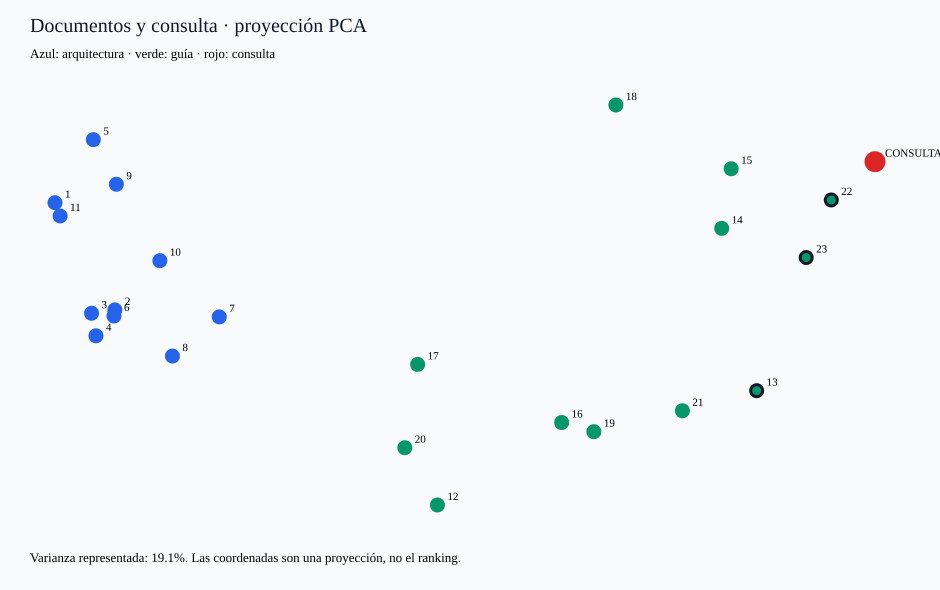

Número,ID,Recuperado
1,arch_convnexttiny,False
2,arch_densenet121,False
3,arch_efficientnetb0,False
4,arch_efficientnetv2b0,False
5,arch_inceptionv3,False
6,arch_mobilenetv2,False
7,arch_mobilenetv3small,False
8,arch_nasnetmobile,False
9,arch_resnet50v2,False
10,arch_vgg16,False


In [8]:
vector_consulta = np.asarray(kb.embedder.embed([CONSULTA]), dtype=float)
matriz = np.vstack([vectores, vector_consulta])
centrada = matriz - matriz.mean(axis=0)
u, s, vt = np.linalg.svd(centrada, full_matrices=False)
xy = u[:, :2] * s[:2]
varianza = (s[:2] ** 2).sum() / (s ** 2).sum() if np.any(s) else 0.0
minimo, rango = xy.min(axis=0), np.ptp(xy, axis=0)
pantalla = (xy - minimo) / np.where(rango == 0, 1, rango)
seleccion = {d.id for d in recuperados}
partes = ['<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 940 590" role="img" aria-label="PCA de documentos y consulta">',
          '<rect width="940" height="590" fill="#f8fafc"/>',
          '<text x="30" y="32" font-size="20" fill="#0f172a">Documentos y consulta · proyección PCA</text>',
          '<text x="30" y="58" font-size="13">Azul: arquitectura · verde: guía · rojo: consulta</text>']
for i, nombre in enumerate(ids + ['CONSULTA']):
    x, y = 55 + pantalla[i, 0] * 820, 505 - pantalla[i, 1] * 400
    color = '#dc2626' if nombre == 'CONSULTA' else '#2563eb' if nombre.startswith('arch_') else '#059669'
    radio = 9 if nombre == 'CONSULTA' else 6
    borde = '#0f172a' if nombre in seleccion else color
    partes.append(f'<circle cx="{x:.2f}" cy="{y:.2f}" r="{radio}" fill="{color}" stroke="{borde}" stroke-width="3"><title>{escape(nombre)}</title></circle>')
    etiqueta = 'CONSULTA' if nombre == 'CONSULTA' else str(i + 1)
    partes.append(f'<text x="{x + 10:.2f}" y="{y - 5:.2f}" font-size="11">{etiqueta}</text>')
partes.append(f'<text x="30" y="562" font-size="13">Varianza representada: {varianza:.1%}. Las coordenadas son una proyección, no el ranking.</text></svg>')
grafico_svg = ''.join(partes)
display(SVG(grafico_svg))
tabla([{'Número': i + 1, 'ID': nombre, 'Recuperado': nombre in seleccion} for i, nombre in enumerate(ids)])


## 9. Evaluar las 10 preguntas de referencia

Precisión@k = relevantes recuperados / k. Recall@k (exhaustividad) = relevantes recuperados /
relevantes etiquetados. La tabla permite ver errores concretos. Las etiquetas también necesitan revisión:
un documento sin etiqueta relevante no necesariamente es irrelevante.

Con la referencia actual hay 23 etiquetas en 10 preguntas (2–3 por pregunta). A k=5, el techo
matemático de la precisión media es **23 / 50 = 0.46**, incluso si recuperas todos los relevantes.
Esta referencia no permite demostrar una meta de precisión@5 ≥ 0.70 sin revisar el protocolo y las etiquetas.


In [9]:
referencias = json.loads((SOURCE / 'knowledge/reference_queries.json').read_text('utf-8'))
K_EVAL = 3
if not 1 <= K_EVAL <= len(ids):
    raise ValueError('K_EVAL fuera de rango.')
filas_eval = []
for ref in referencias:
    esperados = set(ref['relevant'])
    assert esperados <= set(ids), 'Referencia a un documento inexistente'
    obtenidos = [d.id for d in kb.query(ref['query'], k=K_EVAL)]
    aciertos = len(set(obtenidos) & esperados)
    filas_eval.append({'Consulta': ref['query'], 'Esperados': ', '.join(ref['relevant']),
                       'Obtenidos': ', '.join(obtenidos),
                       'Precisión': round(aciertos / K_EVAL, 3),
                       'Recall': round(aciertos / len(esperados), 3)})
tabla(filas_eval)
metricas = kb.evaluate(k=K_EVAL)
print(json.dumps(metricas, indent=2, ensure_ascii=False))
print('Techo de precisión con estas etiquetas:',
      round(sum(min(K_EVAL, len(set(r['relevant']))) for r in referencias) / (len(referencias) * K_EVAL), 3))


Consulta,Esperados,Obtenidos,Precisión,Recall
dataset con muy pocas imágenes por clase,"guide_small_dataset, guide_transfer_learning, guide_data_augmentation","guide_small_dataset, guide_transfer_learning, guide_class_imbalance",0.667,0.667
qué hacer cuando una clase tiene muchos más ejemplos que otra,"guide_class_imbalance, guide_metrics","guide_class_imbalance, guide_transfer_learning, arch_inceptionv3",0.333,0.5
tamaño de lote para GPU de 4 GB de memoria,"guide_batch_size, guide_limited_resources","guide_batch_size, arch_densenet121, arch_resnet50v2",0.333,0.5
rango de tasa de aprendizaje para entrenar la cabeza con backbone congelado,"guide_learning_rate, guide_transfer_learning","guide_learning_rate, guide_transfer_learning, guide_limited_resources",0.667,1.0
modelo muy grande con demasiados parámetros no recomendado para pymes,"arch_vgg16, guide_limited_resources","guide_class_imbalance, arch_efficientnetv2b0, arch_resnet50v2",0.0,0.0
detener configuraciones malas temprano para ahorrar cómputo,"guide_early_stopping, guide_limited_resources","guide_early_stopping, arch_efficientnetb0, guide_limited_resources",0.667,1.0
arquitectura más ligera para dispositivos móviles con latencia mínima,"arch_mobilenetv3small, arch_mobilenetv2","arch_mobilenetv3small, guide_small_dataset, guide_large_dataset",0.333,0.5
"muchas imágenes de entrenamiento, modelo de mayor capacidad","guide_large_dataset, arch_resnet50v2, arch_convnexttiny","guide_large_dataset, guide_transfer_learning, arch_vgg16",0.333,0.333
resolución 299 de entrada más costosa,"arch_xception, arch_inceptionv3, guide_input_resolution","guide_input_resolution, arch_xception, arch_efficientnetb0",0.667,0.667
qué métricas usar para evaluar el modelo y conjunto de prueba,"guide_metrics, guide_class_imbalance","guide_metrics, guide_small_dataset, guide_class_imbalance",0.667,1.0


{
  "k": 3,
  "n_queries": 10,
  "backend": "hash",
  "precision_at_k": 0.467,
  "recall_at_k": 0.617
}
Techo de precisión con estas etiquetas: 0.767


## 10. ¿Dónde entra el LLM? ¿Esto ya genera una respuesta?

Hasta aquí inspeccionamos **indexación y recuperación**. El sistema completo añade los textos al
contexto del LLM en `candidates.propose_llm()` y valida sus propuestas contra catálogo y rejilla.
La función `Pipeline.n_retrieve()` hace varias consultas y `retrieve_many()` une los resultados,
deduplica IDs y conserva el mayor score de cada documento. Aquí puedes ver ambos métodos originales.

**Sin LLM disponible**, `propose_rules()` selecciona por reglas, perfil y recursos. Los documentos
recuperados se usan para asociar IDs de fuentes; su texto no determina ese ranking. Por tanto,
ejecutar recuperación por sí sola no demuestra que las decisiones hayan sido generadas mediante RAG.
Este notebook no llama APIs ni genera propuestas con LLM.


In [10]:
import ast
def ver_funcion(archivo, nombre):
    source = (SOURCE / 'contexto' / archivo).read_text('utf-8')
    tree = ast.parse(source)
    fn = next(n for n in ast.walk(tree) if isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef)) and n.name == nombre)
    display(Markdown('```python\n' + ast.get_source_segment(source, fn) + '\n```'))

ver_funcion('pipeline.py', 'n_retrieve')
ver_funcion('candidates.py', 'propose_llm')


```python
def n_retrieve(self, s: State) -> State:
        p = self.profile
        bucket = p.size_bucket()
        q = [f"dataset {'pequeño con pocas imágenes' if bucket == 'small' else 'grande con muchas imágenes' if bucket == 'large' else 'mediano'} de clasificación de imágenes",
             "rangos de tasa de aprendizaje y dropout", "tamaño de lote y memoria de GPU", "recursos computacionales limitados",
             "arquitecturas ligeras con transferencia de aprendizaje", "descarte temprano de configuraciones", "métricas de evaluación"]
        if p.imbalance_ratio > 1.5:
            q.append("clases desbalanceadas")
        if self.cfg.use_case:
            q.append(self.cfg.use_case)
        self.docs = self.kb.retrieve_many(q, k=3)
        self.log.emit("rag", f"{len(self.docs)} documentos recuperados", docs=[d.to_dict() for d in self.docs])
        return {}
```

```python
def propose_llm(profile, docs, cfg, llm: LLM) -> tuple[list[Candidate], list[dict]]:
    ok, discarded = _allowed(cfg)
    system = ("Eres un ingeniero de ML que acota el espacio de búsqueda de modelos de clasificación de imágenes. "
              "Usa EXCLUSIVAMENTE la evidencia recuperada y el perfil del dataset. Justifica cada decisión.")
    user = json.dumps({
        "perfil_dataset": profile.to_dict(),
        "caso_de_uso": cfg.use_case,
        "nivel_recursos": cfg.resource_tier,
        "preentrenado": cfg.pretrained,
        "evidencia_recuperada": [{"id": d.id, "titulo": d.title, "texto": d.text} for d in docs],
        "arquitecturas_permitidas": {n: {"params_m": s.params_m} for n, s in ok.items()},
        "rejilla": {"lr": LR_GRID, "dropout": DROPOUT_GRID, "batch": BATCH_GRID, "augment": AUGMENT_GRID},
        "instrucciones": (
            f"Elige entre 1 y {cfg.max_candidates} arquitecturas permitidas. Devuelve JSON: "
            '{"candidatas":[{"arquitectura":str,"justificacion":str,"fuentes":[ids],"lr":[..],"dropout":[..],'
            '"batch":[..],"augment":[..]}],"descartadas":[{"arquitectura":str,"razon":str}]}. '
            "Los valores deben salir de la rejilla; elige 2-3 valores por hiperparámetro."),
    }, ensure_ascii=False)
    data = llm.complete_json(system, user)
    default = default_space(profile, cfg)
    doc_ids = {d.id for d in docs}
    cands = []
    for item in data.get("candidatas", []):
        a = item.get("arquitectura")
        if a not in ok or any(c.architecture == a for c in cands):
            continue
        cands.append(Candidate(
            f"c{len(cands)+1}", a, str(item.get("justificacion", ""))[:500],
            [s for s in item.get("fuentes", []) if s in doc_ids],
            _subset(item.get("lr"), LR_GRID, default["lr_values"]),
            _subset(item.get("dropout"), DROPOUT_GRID, default["dropout_values"]),
            _subset(item.get("batch"), BATCH_GRID, default["batch_sizes"]),
            _subset(item.get("augment"), AUGMENT_GRID, default["augment_values"]),
            _img_size(ok[a], cfg)))
        if len(cands) == cfg.max_candidates:
            break
    if not cands:
        raise ValueError("El LLM no propuso candidatas válidas")
    picked = {c.architecture for c in cands}
    reasons = {d.get("arquitectura"): d.get("razon") for d in data.get("descartadas", [])}
    for n in ok:
        if n not in picked:
            discarded.append({"architecture": n, "reason": reasons.get(n) or "No seleccionada por el agente."})
    return cands, discarded
```

In [11]:
consultas_ejemplo = [
    'dataset pequeño con pocas imágenes de clasificación de imágenes',
    'tamaño de lote y memoria de GPU',
    'arquitecturas ligeras con transferencia de aprendizaje',
]  # subconjunto ilustrativo: el pipeline usa más consultas según el perfil
evidencia = kb.retrieve_many(consultas_ejemplo, k=3)
contexto_para_llm = [{'id': d.id, 'titulo': d.title, 'texto': d.text} for d in evidencia]
print('Consultas:', len(consultas_ejemplo), '→ documentos únicos:', len(evidencia))
print('Así luce el campo evidencia_recuperada del contexto para el LLM:')
print(json.dumps(contexto_para_llm, ensure_ascii=False, indent=2))


Consultas: 3 → documentos únicos: 8
Así luce el campo evidencia_recuperada del contexto para el LLM:
[
  {
    "id": "guide_batch_size",
    "titulo": "Tamaño de lote",
    "texto": "El tamaño de lote está limitado por la memoria de video. En GPU de 4 GB, como una GTX 1650, se recomiendan lotes de 16 o 32 con modelos ligeros; lotes de 64 suelen exceder la memoria con resoluciones de 224x224 o mayores. En GPU de 8 GB o más se pueden usar lotes de 32 a 64."
  },
  {
    "id": "guide_small_dataset",
    "titulo": "Datasets pequeños: pocas imágenes por clase",
    "texto": "Con menos de unos 1000 imágenes de entrenamiento o pocas decenas por clase, conviene elegir arquitecturas ligeras con transferencia de aprendizaje, usar aumento de datos y dropout alto de 0.2 a 0.4 para evitar sobreajuste. Los modelos grandes tienden a sobreajustar con pocos datos y no aportan mejora. Usar validación estratificada."
  },
  {
    "id": "arch_efficientnetv2b0",
    "titulo": "EfficientNetV2B0 (Keras Appli

## 11. Guardar una copia legible de la inspección

Se exportan JSON con documentos, metadatos, vectores, consulta y métricas, y el gráfico SVG.
El JSON sirve para inspección; no es un respaldo nativo completo de Chroma.
Cambia `DESCARGAR` a `True` si quieres descargar el ZIP desde Colab.
Las carpetas temporales de Colab pueden desaparecer cuando termine la sesión.


In [12]:
import zipfile
EXPORT = BASE / 'exportacion'
EXPORT.mkdir(exist_ok=True)
registros = [{'id': doc_id, 'document': text, 'metadata': meta, 'embedding': v.tolist()}
             for doc_id, text, meta, v in zip(ids, textos, metadatos, vectores)]
contenido = {'snapshot_id': SNAPSHOT_ID, 'chroma_version': chromadb.__version__,
             'backend': kb.embedder.name, 'collection': kb.collection.name,
             'records': registros, 'query': CONSULTA,
             'retrieved': [d.to_dict() for d in recuperados], 'evaluation': metricas}
(EXPORT / 'inspeccion_rag.json').write_text(json.dumps(contenido, ensure_ascii=False, indent=2), encoding='utf-8')
(EXPORT / 'mapa_rag.svg').write_text(grafico_svg, encoding='utf-8')
(EXPORT / 'manifest_fuentes.json').write_text(json.dumps(MANIFEST, indent=2), encoding='utf-8')
zip_path = BASE / 'inspeccion_rag.zip'
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zf:
    for p in EXPORT.iterdir():
        zf.write(p, p.name)
    for p in SOURCE.rglob('*'):
        if p.is_file() and '__pycache__' not in p.parts:
            zf.write(p, 'fuentes/' + p.relative_to(SOURCE).as_posix())
print('Exportación:', zip_path)
DESCARGAR = False
if DESCARGAR:
    from google.colab import files
    files.download(str(zip_path))


Exportación: C:\Users\rober\AppData\Local\Temp\automl_rag_b263a4684b68\inspeccion_rag.zip


## Para seguir explorando tu proyecto

- En tu PC, abre cualquier `src/automl_agents/knowledge/*.md`: ya puedes leer la base sin Colab.
- Revisa `runs/<id>/events.jsonl`, evento `rag`, para ver IDs y scores de una corrida real.
- En `runs/<id>/reports/01_criterios_acotacion.json`, revisa `mode`, `criteria.retrieved_docs`
  y las fuentes de cada candidata. `mode` distingue si se usó `llm` o `reglas`.
- Para ampliar el conocimiento, añade Markdown al directorio `knowledge/` y vuelve a construir
  el índice. El código actual hace `upsert`, pero **no elimina registros antiguos** si borras o
  renombras documentos: usa un índice nuevo al experimentar con una KB modificada.
- Compara `hash` y `sentence-transformers` con las mismas consultas y etiquetas. Mide la mejora;
  no la des por supuesta.

Referencias de uso: [documentación oficial de Chroma](https://docs.trychroma.com/docs/collections/manage-collections)
y [preguntas frecuentes de Google Colab](https://research.google.com/colaboratory/faq.html).
